In [1]:
from IPython.display import display, Markdown
import pandas as pd
import seaborn as sns
from scipy.stats import spearmanr
import scipy.stats

In [6]:
filepath = 'data/audioData.csv'
audioData = pd.read_csv(filepath)

# columns_with_all_zeros = audioData.columns[audioData.eq(0).all()]

# # Print the column names with all zeros
# for col_name in columns_with_all_zeros:
#     print(f"Column '{col_name}' has all values equal to 0.")

pitchAverages = audioData[audioData != 0].mean(axis=0)
pitchAverages = pitchAverages.reset_index(drop=False)
pitchAverages.columns = ['Clip_ID', 'pitchAverage']
# DROP 0 VALUES 
pitchAverages = pitchAverages[pitchAverages['Clip_ID'] != 'cut_feb2203-human-20']
pitchAverages = pitchAverages[pitchAverages['Clip_ID'] != 'cut_feb2803-human-13']
# print("Column Averages (excluding 0s):")
# print(pitchAverages)

## Distribution of the mean pitch per audio clip

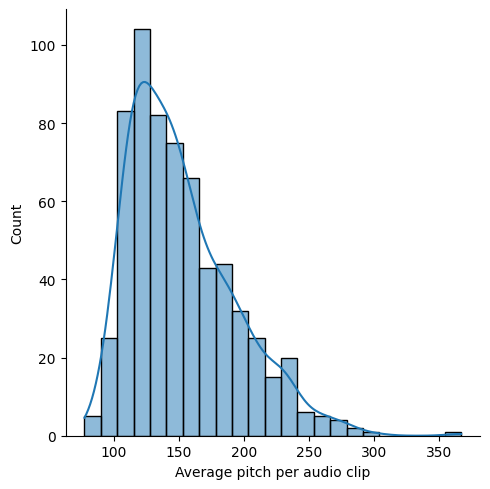

In [7]:
display(Markdown('## Distribution of the mean pitch per audio clip'))
plot = sns.displot(pitchAverages['pitchAverage'], kde=True)
plot.set_axis_labels('Average pitch per audio clip', "Count")

In [8]:
%run ./dataManipulationFunctions.ipynb

In [9]:
bigFive = ['Extraversion', 'Agreeableness', 'Conscientiousness', 'Neuroticism', 'Openness']
data = pd.DataFrame(medianScoresPerClip(), columns=['Clip_ID', 'Extraversion', 'Agreeableness', 'Conscientiousness', 'Neuroticism', 'Openness'])
pitchWithFeaturesAv = pd.merge(pitchAverages, data, on='Clip_ID')


In [10]:
metadata = pd.read_csv('data/metadata.csv')

sexId = metadata.loc[:,['Clip_ID', 'Gender']].copy()
mergedDfAv = pd.merge(pitchWithFeaturesAv, sexId, on='Clip_ID')

femaleOnlyAv = mergedDfAv[mergedDfAv['Gender'] == 'F']
maleOnlyAv = mergedDfAv[mergedDfAv['Gender'] == 'M']

In [11]:
# T TEST to see the difference between the pitch for female and male

tStatistic, pValue = scipy.stats.ttest_ind(a=femaleOnlyAv['pitchAverage'], b=maleOnlyAv['pitchAverage'], equal_var=True)
result = [tStatistic, pValue]
print(result)

[7.091917143715987, 3.5332355718679572e-12]


In [17]:
data = [[femaleOnlyAv['pitchAverage'].mean(), femaleOnlyAv['pitchAverage'].min(), femaleOnlyAv['pitchAverage'].max()], [maleOnlyAv['pitchAverage'].mean(), maleOnlyAv['pitchAverage'].min(), maleOnlyAv['pitchAverage'].max()]]
dfPitchInfo = pd.DataFrame(data, columns=['Mean f_0', 'Minimum f_0', 'Maximum f_0'], index=['Female', 'Male'])
dfPitchInfo

,Mean f_0,Minimum f_0,Maximum f_0
Female,173.450310,117.656982,283.996488
Male,146.466992,77.286834,367.320230


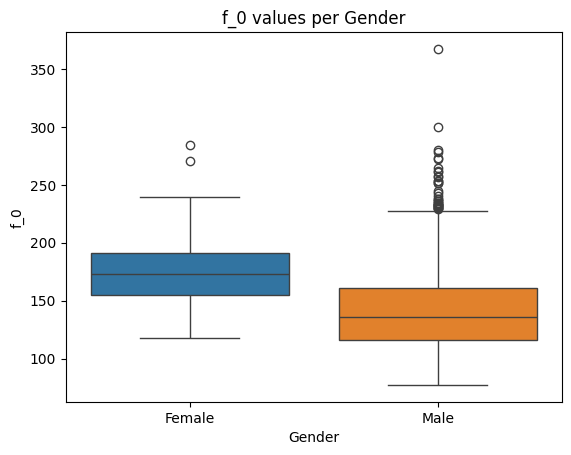

In [18]:
labels = ['Female'] * len(femaleOnlyAv['pitchAverage']) + ['Male'] * len(maleOnlyAv['pitchAverage'])
df = np.concatenate((femaleOnlyAv['pitchAverage'],maleOnlyAv['pitchAverage']),axis=0)
df = pd.DataFrame({'f_0': df, 'Gender' : labels})
box = sns.boxplot(x='Gender', y='f_0', hue='Gender', data=df, legend=False)
plt.title('f_0 values per Gender')
plt.show()

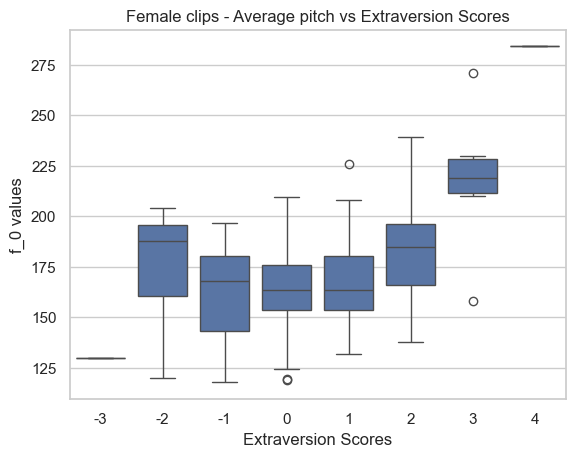

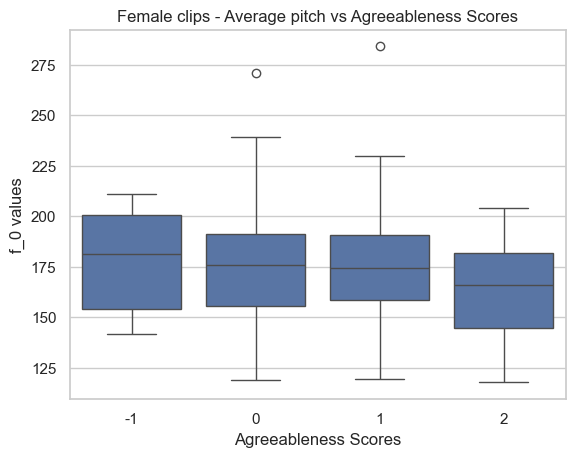

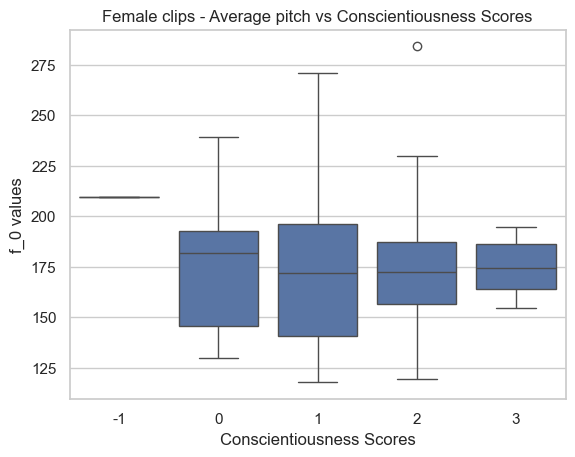

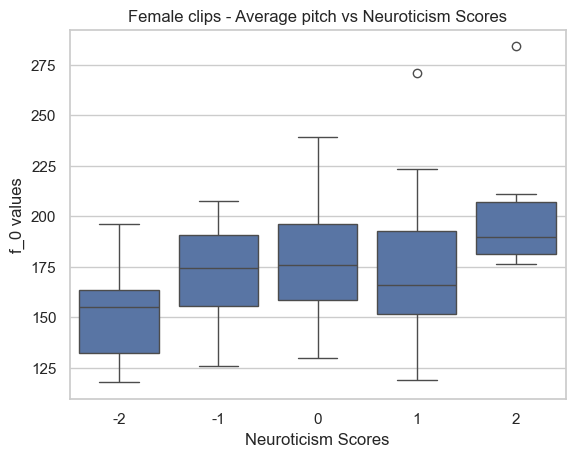

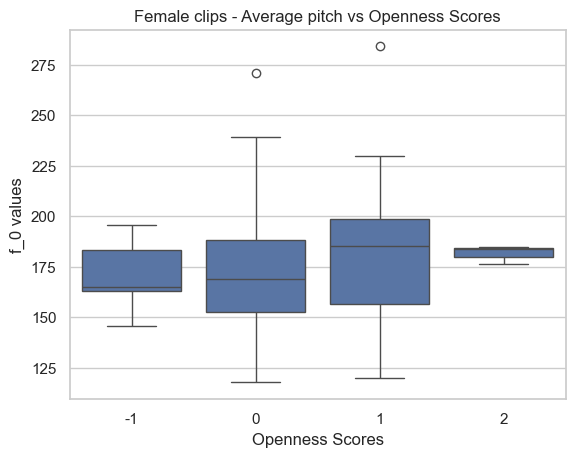

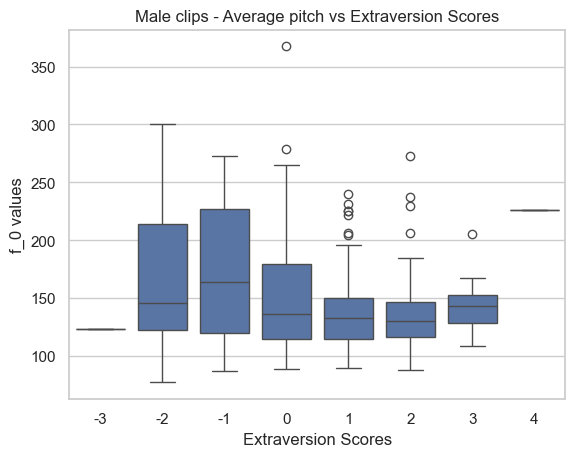

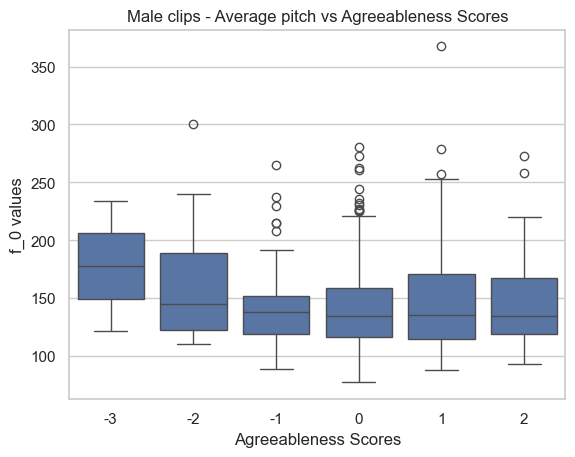

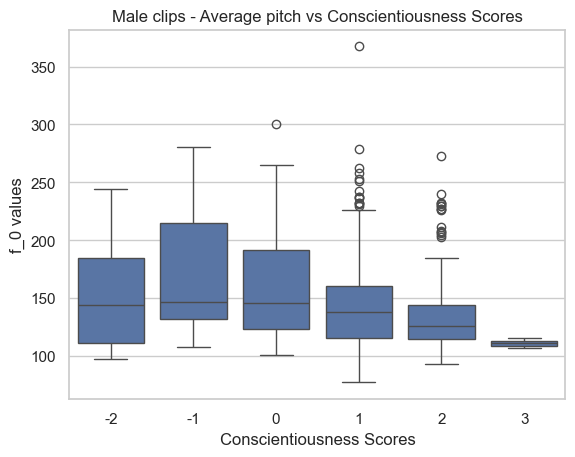

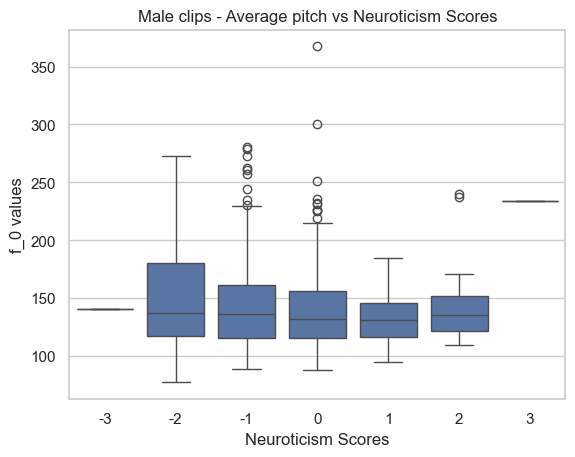

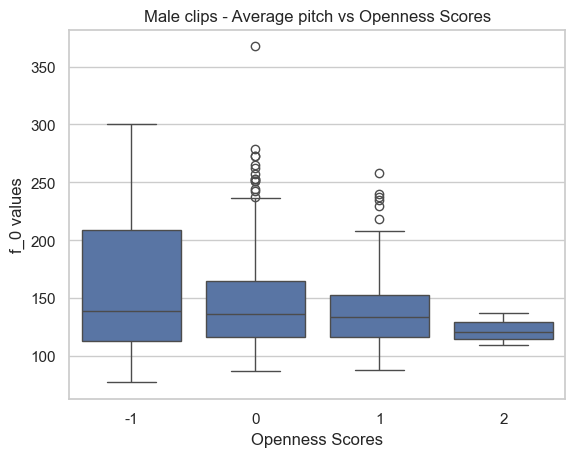

In [33]:
for trait in bigFive:    
    pitchData = femaleOnlyAv['pitchAverage']
    traitScores  = femaleOnlyAv[trait]
    # Create a DataFrame using the two arrays
    # import pandas as pd
    df = pd.DataFrame({f'{trait} Scores': traitScores, 'f_0 values': pitchData})

    sns.boxplot(x=f'{trait} Scores', y='f_0 values', data=df)
    plt.title(f'Female clips - Average pitch vs {trait} Scores')
    plt.xlabel(f'{trait} Scores')
    plt.ylabel('f_0 values')
    # plt.title('Box Plot of Array2 grouped by Array1')
    plt.show()

for trait in bigFive:    
    pitchData = maleOnlyAv['pitchAverage']
    traitScores  = maleOnlyAv[trait]
    # Create a DataFrame using the two arrays
    # import pandas as pd
    df = pd.DataFrame({f'{trait} Scores': traitScores, 'f_0 values': pitchData})

    sns.boxplot(x=f'{trait} Scores', y='f_0 values', data=df)
    plt.title(f'Male clips - Average pitch vs {trait} Scores')
    plt.xlabel(f'{trait} Scores')
    plt.ylabel('f_0 values')
    # plt.title('Box Plot of Array2 grouped by Array1')
    plt.show()

## Female Average pitch vs trait

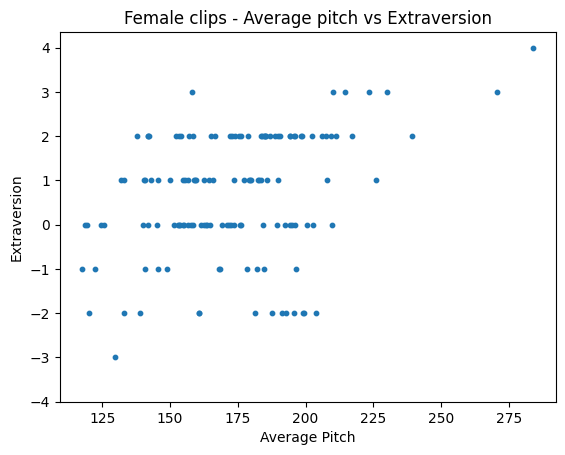

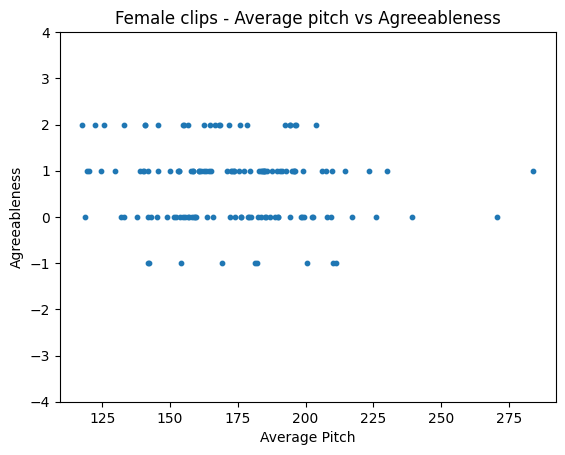

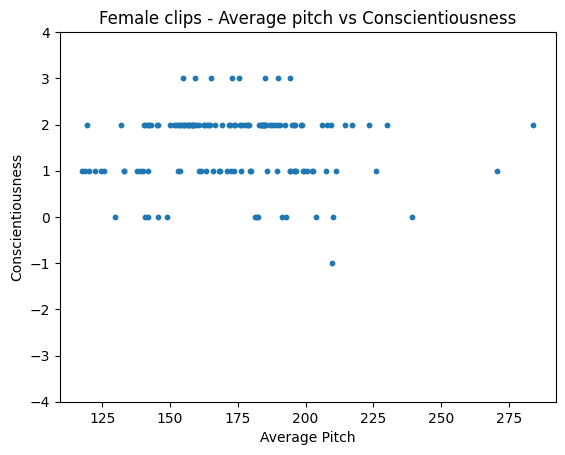

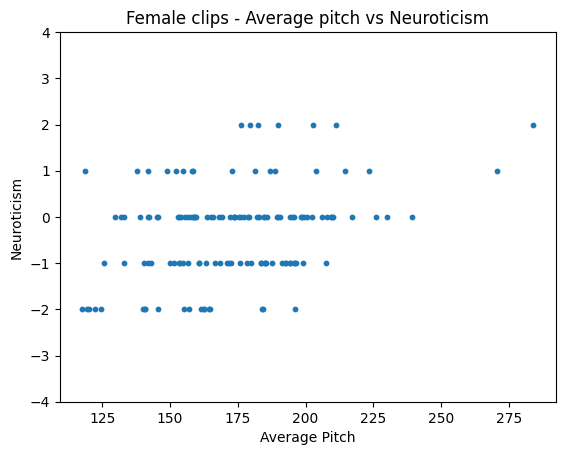

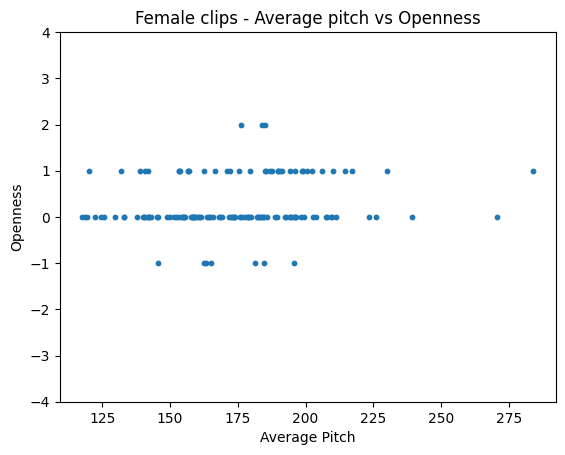

## Male Average pitch vs trait

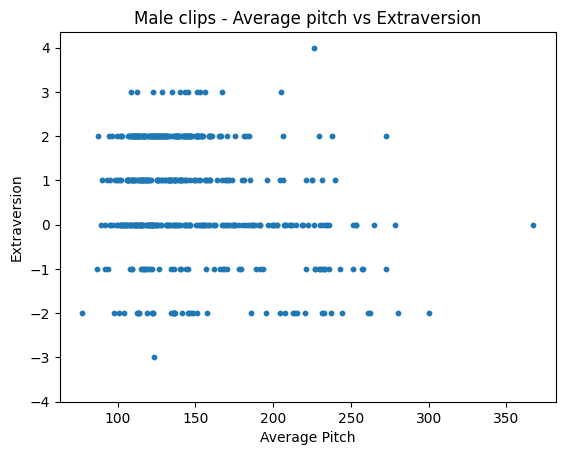

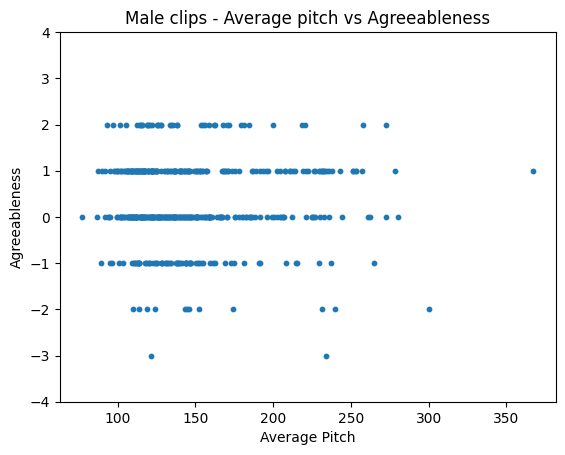

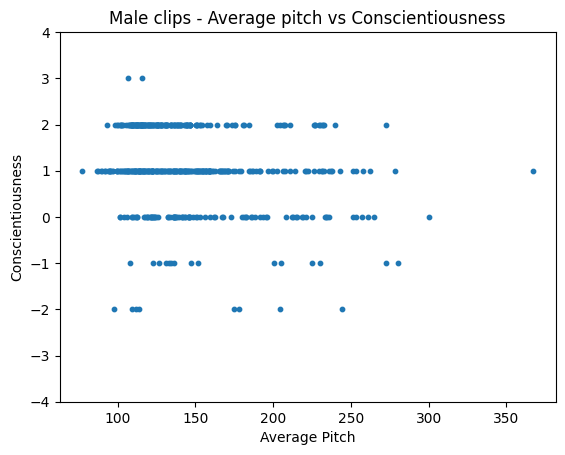

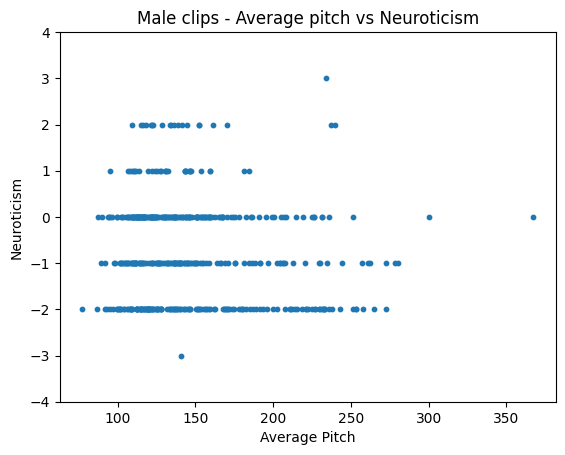

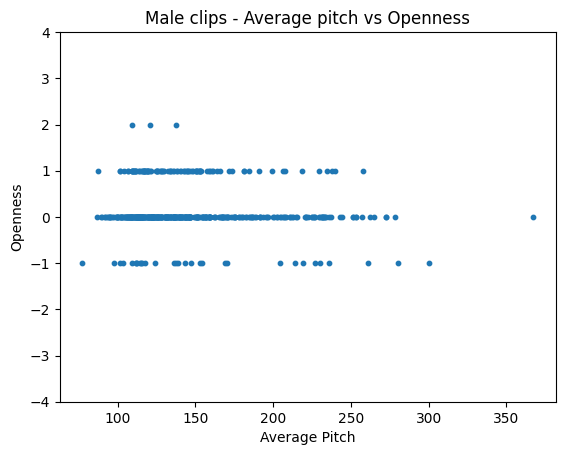

In [15]:
display(Markdown('## Female Average pitch vs trait'))
for trait in bigFive:    
    plt.scatter(femaleOnlyAv['pitchAverage'], femaleOnlyAv[trait], s=10)
    plt.xlabel('Average Pitch')
    plt.ylabel(trait)
    plt.title(f'Female clips - Average pitch vs {trait}')
    plt.yticks([-4,-3,-2,-1,0,1,2,3,4]) 
    plt.show()
    
display(Markdown('## Male Average pitch vs trait'))
for trait in bigFive:    
    plt.scatter(maleOnlyAv['pitchAverage'], maleOnlyAv[trait], s=10)
    plt.xlabel('Average Pitch')
    plt.ylabel(trait)
    plt.title(f'Male clips - Average pitch vs {trait}')
    plt.yticks([-4,-3,-2,-1,0,1,2,3,4]) 
    plt.show()



In [23]:
display(Markdown('## Female Average Pitch'))
femaleCorrelations = pd.DataFrame(index=bigFive, columns=['rho', 'p'])
for trait in bigFive:
    rho, p = spearmanr(femaleOnlyAv['pitchAverage'], femaleOnlyAv[trait])
    femaleCorrelations.loc[trait] = [rho, p]

display(femaleCorrelations)

display(Markdown('## Male Average Pitch'))
maleCorrelations = pd.DataFrame(index=bigFive, columns=['rho', 'p'])
for trait in bigFive:
    rho, p = spearmanr(maleOnlyAv['pitchAverage'],maleOnlyAv[trait])
    maleCorrelations.loc[trait] = [rho, p]

display(maleCorrelations)



## Female Average Pitch

,rho,p
Extraversion,0.299961,0.000369
Agreeableness,-0.108466,0.207071
Conscientiousness,-0.008762,0.919055
Neuroticism,0.270054,0.001416
Openness,0.159689,0.062327


## Male Average Pitch

,rho,p
Extraversion,-0.166116,0.000188
Agreeableness,-0.00446,0.920685
Conscientiousness,-0.217335,0.000001
Neuroticism,-0.071829,0.108316
Openness,-0.040626,0.364172
